<a href="https://colab.research.google.com/github/fatihludyaryasatya/brightness-adjustment/blob/main/brightness_adjustment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
# Instal library (agar bisa membaca HEIC dari iPhone)
!pip -q install pillow-heif

In [15]:
# Upload gambar


from google.colab import drive
drive.mount('/content/drive')

import os, glob
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

cari = glob.glob('/content/drive/MyDrive/**/semester 5/**PCD/**IMG_1637.JPEG', recursive=True)
print('Ditemukan:', cari)

Mounted at /content/drive
Ditemukan: ['/content/drive/MyDrive/semester 5/PCD/IMG_1637.JPEG']


In [16]:
# Metadata gambar (bagian “kaya pengetahuan”)
from PIL import Image, ExifTags
import pillow_heif, numpy as np, os
pillow_heif.register_heif_opener()

img = Image.open(nama)
print("Format      :", img.format)
print("Ukuran      :", img.size, "(lebar x tinggi)")
print("Mode warna  :", img.mode)
print("Ukuran file :", os.path.getsize(nama)/1024, "KB")
print("Total piksel:", img.size[0]*img.size[1])

exif = img.getexif()
for k, v in exif.items():
    print(ExifTags.TAGS.get(k, k), ":", v)

Format      : JPEG
Ukuran      : (2048, 1536) (lebar x tinggi)
Mode warna  : RGB
Ukuran file : 794.4306640625 KB
Total piksel: 3145728
GPSInfo : 2436
ResolutionUnit : 2
ExifOffset : 228
Make : Apple
Model : iPhone 11
Software : 18.7.1
Orientation : 1
DateTime : 2026:04:17 12:32:38
YCbCrPositioning : 1
XResolution : 72.0
YResolution : 72.0
HostComputer : iPhone 11


In [17]:
# Buktikan gambar = susunan angka
arr = np.array(img.convert("RGB"))
print("Tipe data :", type(arr))
print("Shape     :", arr.shape, "-> (tinggi, lebar, 3 kanal RGB)")
print("dtype     :", arr.dtype, "| min:", arr.min(), "| max:", arr.max())
print("\nPiksel (0,0) [R,G,B]:", arr[0, 0])
print("\nBlok 5x5 kanal Merah:\n", arr[:5, :5, 0])
print("\nBlok 5x5 kanal Hijau:\n", arr[:5, :5, 1])
print("\nBlok 5x5 kanal Biru:\n", arr[:5, :5, 2])

Tipe data : <class 'numpy.ndarray'>
Shape     : (1536, 2048, 3) -> (tinggi, lebar, 3 kanal RGB)
dtype     : uint8 | min: 0 | max: 255

Piksel (0,0) [R,G,B]: [154 180 207]

Blok 5x5 kanal Merah:
 [[154 154 154 155 156]
 [154 154 155 155 157]
 [155 155 155 156 157]
 [155 155 156 157 157]
 [155 155 156 157 158]]

Blok 5x5 kanal Hijau:
 [[180 180 180 181 182]
 [180 180 181 181 183]
 [181 181 181 182 183]
 [181 181 182 183 183]
 [181 181 182 183 184]]

Blok 5x5 kanal Biru:
 [[207 207 207 208 209]
 [207 207 208 208 210]
 [208 208 208 209 210]
 [208 208 209 210 210]
 [208 208 209 210 211]]


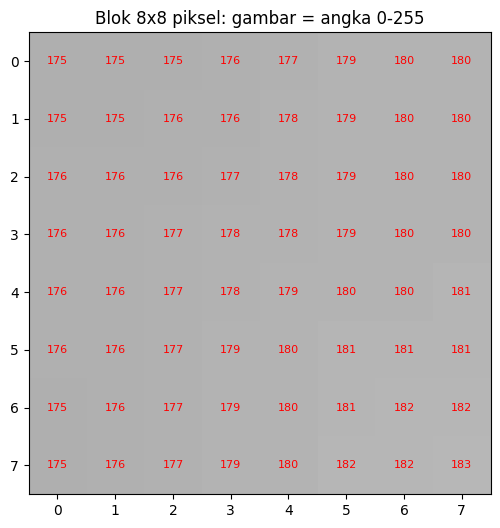

In [18]:
# Tampilkan angka di atas gambar (grayscale 8x8) dan simpan CSV
import matplotlib.pyplot as plt
gray = np.array(img.convert("L"))
blok = gray[:8, :8]
np.savetxt("gray_8x8.csv", blok, fmt="%d", delimiter=",")
np.save("piksel_5x5.npy", arr[:5, :5])

plt.figure(figsize=(6,6))
plt.imshow(blok, cmap="gray", vmin=0, vmax=255)
for i in range(8):
    for j in range(8):
        plt.text(j, i, blok[i, j], ha="center", va="center",
                 color="red", fontsize=8)
plt.title("Blok 8x8 piksel: gambar = angka 0-255")
plt.savefig("blok_8x8.png", dpi=150)
plt.show()

In [19]:
# Rekonstruksi, angka kembali jadi gambar
rekon = Image.fromarray(arr)
rekon.save("hasil_rekonstruksi.png")
print("Identik dengan aslinya?", np.array_equal(np.array(rekon), arr))

Identik dengan aslinya? True


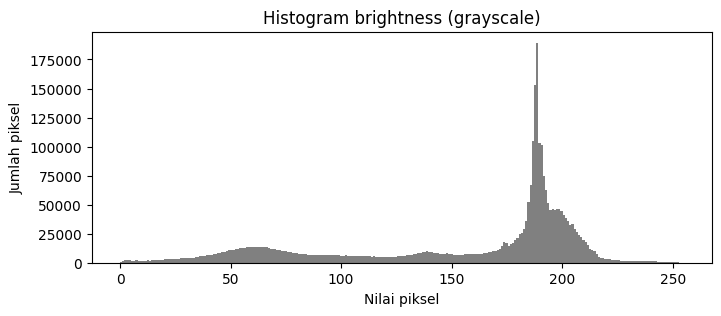

In [20]:
# Histogram distribusi angka
plt.figure(figsize=(8,3))
plt.hist(gray.ravel(), bins=256, range=(0,255), color="gray")
plt.title("Histogram brightness (grayscale)")
plt.xlabel("Nilai piksel"); plt.ylabel("Jumlah piksel")
plt.savefig("histogram_asli.png", dpi=150)
plt.show()

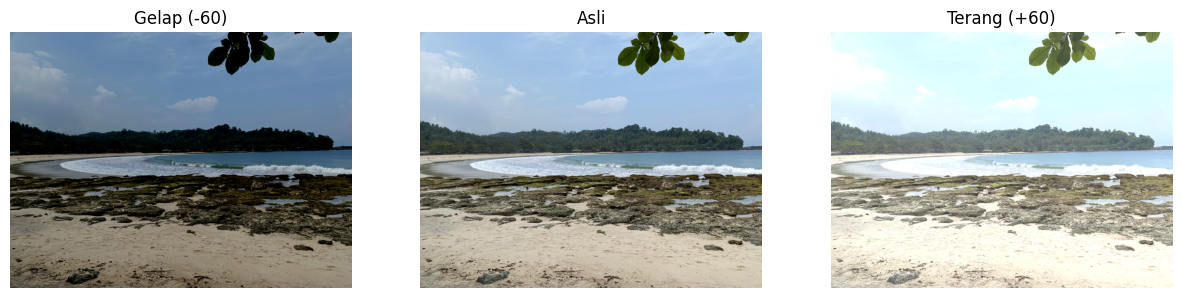

Piksel (0,0) asli  : [154 180 207]
Piksel (0,0) +60   : [214 240 255]
Piksel (0,0) -60   : [ 94 120 147]
Rata-rata asli/+60/-60: 155.1022482977973 209.10125393337674 97.73292075263129


In [21]:
# Ubah kecerahan dengan menambah/mengurangi angka piksel
def brightness(a, beta):
    return np.clip(a.astype(np.int16) + beta, 0, 255).astype(np.uint8)

terang = brightness(arr, +60)
gelap  = brightness(arr, -60)

fig, ax = plt.subplots(1, 3, figsize=(15,5))
for a, im, t in zip(ax, [gelap, arr, terang], ["Gelap (-60)", "Asli", "Terang (+60)"]):
    a.imshow(im); a.set_title(t); a.axis("off")
plt.savefig("brightness_perbandingan.png", dpi=150)
plt.show()

print("Piksel (0,0) asli  :", arr[0,0])
print("Piksel (0,0) +60   :", terang[0,0])
print("Piksel (0,0) -60   :", gelap[0,0])
print("Rata-rata asli/+60/-60:", arr.mean(), terang.mean(), gelap.mean())

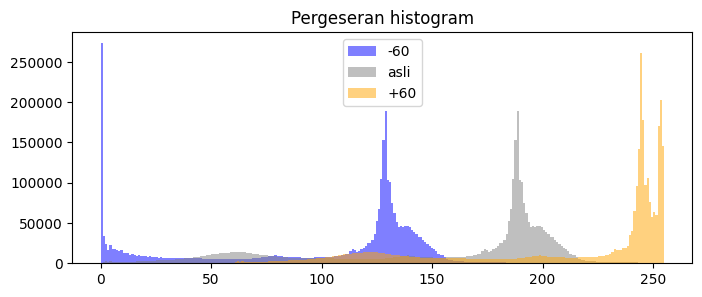

In [22]:
# Histogram setelah brightness, untuk melihat pergeseran
plt.figure(figsize=(8,3))
for im, c, l in [(gelap,"blue","-60"), (arr,"gray","asli"), (terang,"orange","+60")]:
    plt.hist(np.array(Image.fromarray(im).convert("L")).ravel(),
             bins=256, range=(0,255), alpha=0.5, color=c, label=l)
plt.legend(); plt.title("Pergeseran histogram")
plt.savefig("histogram_brightness.png", dpi=150)
plt.show()